In [ ]:
!pip install -q tensorflow-datasets

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Install Kaggle
!pip install -q kaggle

In [ ]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API configured successfully!")

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API configured successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [ ]:
!kaggle datasets download -d karagwaanntreasure/plant-disease-detection

Dataset URL: https://www.kaggle.com/datasets/karagwaanntreasure/plant-disease-detection
License(s): MIT
100% 534M/534M [00:06<00:00, 90.6MB/s]



In [ ]:
!unzip -q plant-disease-detection.zip -d /content/plant_dataset

In [ ]:
import os

print("Dataset downloaded successfully!")

for root, dirs, files in os.walk("/content/plant_dataset"):
    print(root, "->", len(files), "files")
    if root.count(os.sep) > 4:
        dirs[:] = []

Dataset downloaded successfully!
/content/plant_dataset -> 0 files
/content/plant_dataset/Dataset -> 0 files
/content/plant_dataset/Dataset/Pepper__bell___healthy -> 1478 files
/content/plant_dataset/Dataset/Tomato__Tomato_YellowLeaf__Curl_Virus -> 3209 files
/content/plant_dataset/Dataset/Tomato__Tomato_mosaic_virus -> 373 files
/content/plant_dataset/Dataset/Corn_(maize)___healthy -> 1859 files
/content/plant_dataset/Dataset/Potato___Late_blight -> 1000 files
/content/plant_dataset/Dataset/Apple___Black_rot -> 1987 files
/content/plant_dataset/Dataset/Apple___Cedar_apple_rust -> 1760 files
/content/plant_dataset/Dataset/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot -> 1642 files
/content/plant_dataset/Dataset/Corn_(maize)___Common_rust_ -> 1907 files
/content/plant_dataset/Dataset/Potato___Early_blight -> 1000 files
/content/plant_dataset/Dataset/Tomato_Early_blight -> 1000 files
/content/plant_dataset/Dataset/Tomato__Target_Spot -> 1404 files
/content/plant_dataset/Dataset/Pota

In [ ]:
import zipfile
import glob

zip_files = glob.glob("*.zip")

print("ZIP files found:")
print(zip_files)

if len(zip_files) == 0:
    raise FileNotFoundError("No ZIP dataset was found.")

zip_path = zip_files[0]

extract_path = "/content/plant_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\n✅ Dataset extracted successfully!")
print("Location:", extract_path)

ZIP files found:
['plant-disease-detection.zip']

✅ Dataset extracted successfully!
Location: /content/plant_dataset


In [ ]:
from pathlib import Path

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

for root, dirs, files in os.walk(extract_path):

    image_count = sum(
        1 for f in files
        if Path(f).suffix.lower() in image_extensions
    )

    if image_count > 0:
        print(
            f"{root}  -->  {image_count} images"
        )

/content/plant_dataset/Dataset/Pepper__bell___healthy  -->  1478 images
/content/plant_dataset/Dataset/Tomato__Tomato_YellowLeaf__Curl_Virus  -->  3208 images
/content/plant_dataset/Dataset/Tomato__Tomato_mosaic_virus  -->  373 images
/content/plant_dataset/Dataset/Corn_(maize)___healthy  -->  1859 images
/content/plant_dataset/Dataset/Potato___Late_blight  -->  1000 images
/content/plant_dataset/Dataset/Apple___Black_rot  -->  1987 images
/content/plant_dataset/Dataset/Apple___Cedar_apple_rust  -->  1760 images
/content/plant_dataset/Dataset/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  -->  1642 images
/content/plant_dataset/Dataset/Corn_(maize)___Common_rust_  -->  1907 images
/content/plant_dataset/Dataset/Potato___Early_blight  -->  1000 images
/content/plant_dataset/Dataset/Tomato_Early_blight  -->  1000 images
/content/plant_dataset/Dataset/Tomato__Target_Spot  -->  1404 images
/content/plant_dataset/Dataset/Potato___healthy  -->  152 images
/content/plant_dataset/Dataset/

In [ ]:
def count_images(folder):

    count = 0

    for file in Path(folder).iterdir():

        if file.is_file() and file.suffix.lower() in image_extensions:
            count += 1

    return count


candidate_folders = []

for root, dirs, files in os.walk(extract_path):

    root_path = Path(root)

    subfolders_with_images = []

    for d in dirs:

        subfolder = root_path / d

        try:
            count = count_images(subfolder)
        except:
            count = 0

        if count > 0:
            subfolders_with_images.append(subfolder)

    if len(subfolders_with_images) >= 2:

        total_images = sum(
            count_images(x)
            for x in subfolders_with_images
        )

        candidate_folders.append(
            (root_path, len(subfolders_with_images), total_images)
        )

if not candidate_folders:
    raise Exception(
        "Could not automatically find the class folder structure."
    )

candidate_folders.sort(
    key=lambda x: x[2],
    reverse=True
)

DATA_DIR = candidate_folders[0][0]

print("✅ Dataset class directory found:")
print(DATA_DIR)

print("\nNumber of classes detected:")

class_directories = [
    x for x in DATA_DIR.iterdir()
    if x.is_dir()
]

print(len(class_directories))

print("\nClasses:")

for folder in sorted(class_directories):
    print(folder.name)

✅ Dataset class directory found:
/content/plant_dataset/Dataset

Number of classes detected:
23

Classes:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato__Tomato_mosaic_virus
Tomato_healthy


In [ ]:
import pandas as pd

class_counts = {}

for folder in sorted(class_directories):

    count = sum(
        1
        for file in folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    )

    class_counts[folder.name] = count

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

print(class_df)

print("\nTotal images:", class_df["Images"].sum())
print("Total classes:", len(class_df))

                                                Class  Images
0                                  Apple___Apple_scab    2016
1                                   Apple___Black_rot    1987
2                            Apple___Cedar_apple_rust    1760
3                                     Apple___healthy    2008
4   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...    1642
5                         Corn_(maize)___Common_rust_    1907
6                 Corn_(maize)___Northern_Leaf_Blight    1908
7                              Corn_(maize)___healthy    1859
8                       Pepper__bell___Bacterial_spot     997
9                              Pepper__bell___healthy    1478
10                              Potato___Early_blight    1000
11                               Potato___Late_blight    1000
12                                   Potato___healthy     152
13                              Tomato_Bacterial_spot    2127
14                                Tomato_Early_blight    1000
15      

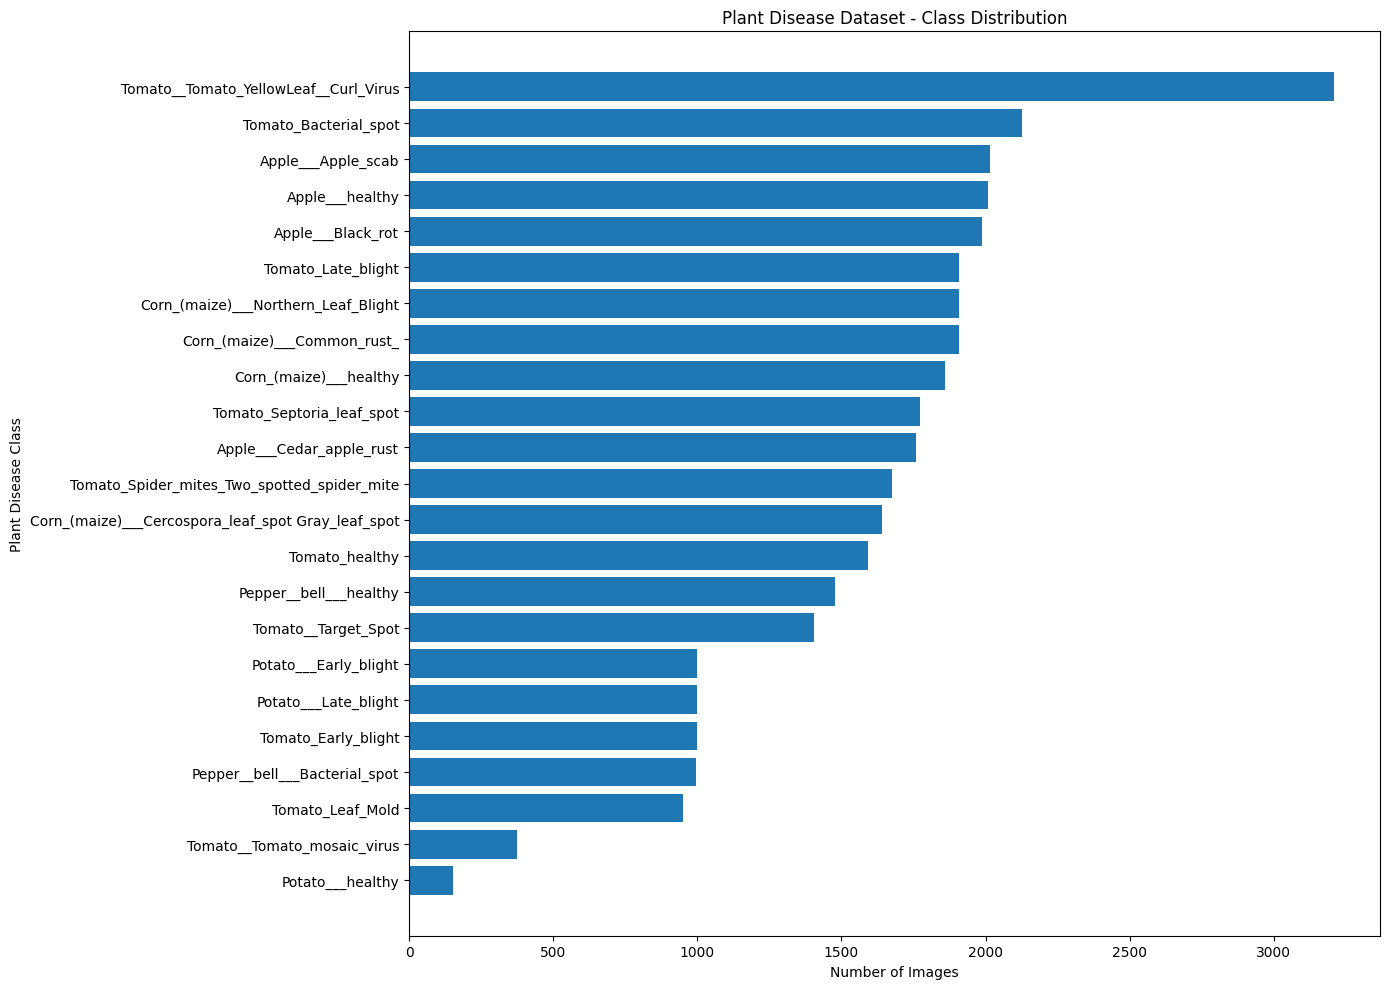

In [ ]:
plt.figure(figsize=(14, 10))

class_df_sorted = class_df.sort_values(
    "Images",
    ascending=True
)

plt.barh(
    class_df_sorted["Class"],
    class_df_sorted["Images"]
)

plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.title("Plant Disease Dataset - Class Distribution")

plt.tight_layout()
plt.show()

In [ ]:
# Define configuration parameters
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels="inferred",
    label_mode="int",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    shuffle=True
)

print("✅ Training dataset loaded!")

Found 35725 files belonging to 23 classes.
Using 28580 files for training.
✅ Training dataset loaded!


In [ ]:
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels="inferred",
    label_mode="int",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    shuffle=False
)

print("✅ Validation/Test dataset loaded!")

Found 35725 files belonging to 23 classes.
Using 7145 files for validation.
✅ Validation/Test dataset loaded!


In [ ]:
class_names = train_ds.class_names

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

print("\nClass names:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 23

Class names:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
5 : Corn_(maize)___Common_rust_
6 : Corn_(maize)___Northern_Leaf_Blight
7 : Corn_(maize)___healthy
8 : Pepper__bell___Bacterial_spot
9 : Pepper__bell___healthy
10 : Potato___Early_blight
11 : Potato___Late_blight
12 : Potato___healthy
13 : Tomato_Bacterial_spot
14 : Tomato_Early_blight
15 : Tomato_Late_blight
16 : Tomato_Leaf_Mold
17 : Tomato_Septoria_leaf_spot
18 : Tomato_Spider_mites_Two_spotted_spider_mite
19 : Tomato__Target_Spot
20 : Tomato__Tomato_YellowLeaf__Curl_Virus
21 : Tomato__Tomato_mosaic_virus
22 : Tomato_healthy


In [ ]:
total_val_test_batches = tf.data.experimental.cardinality(
    val_test_ds
).numpy()

test_batches = total_val_test_batches // 2

val_ds = val_test_ds.take(
    total_val_test_batches - test_batches
)

test_ds = val_test_ds.skip(
    total_val_test_batches - test_batches
)

print("Total validation/test batches:", total_val_test_batches)
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Total validation/test batches: 224
Validation batches: 112
Test batches: 112


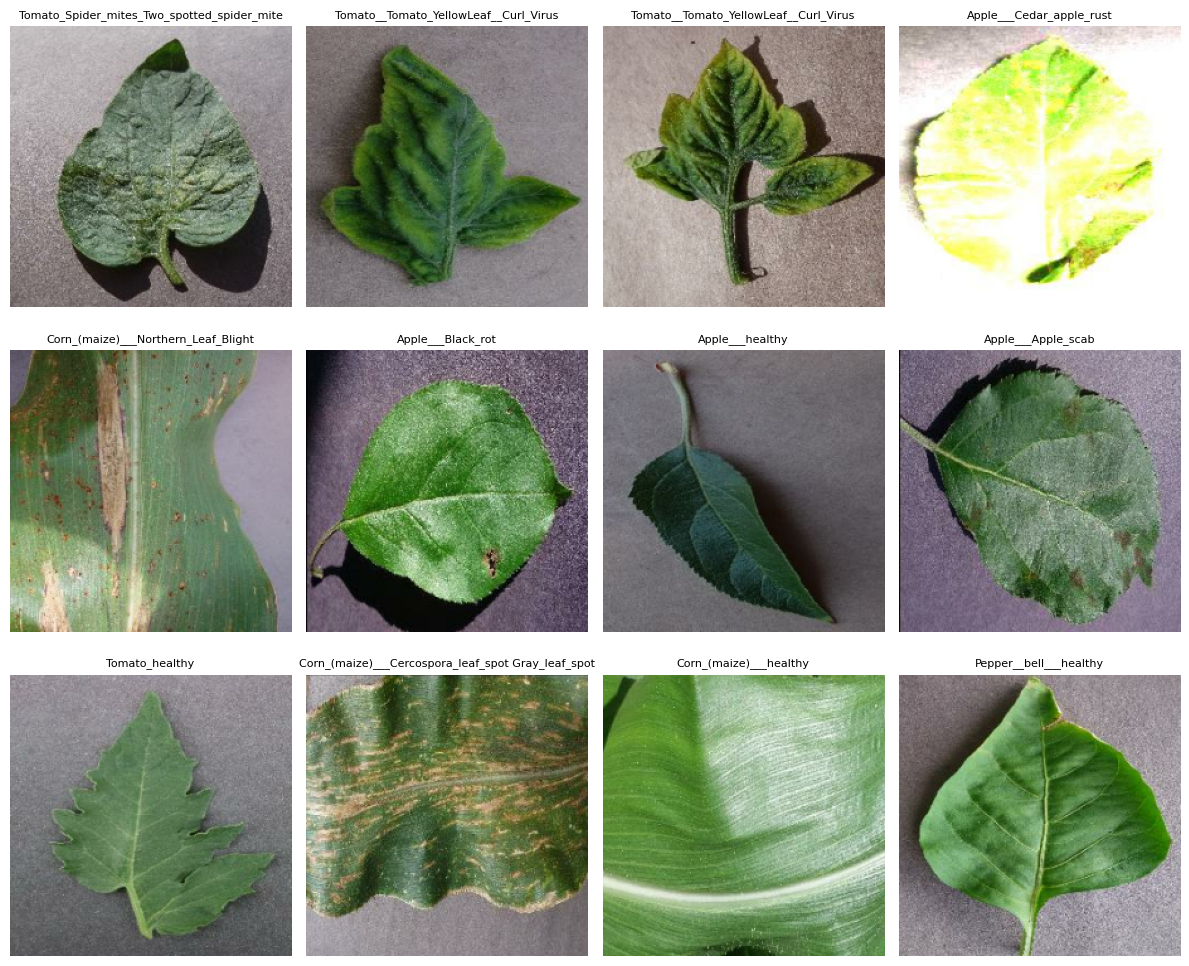

In [ ]:
plt.figure(figsize=(12, 10))

for images, labels in train_ds.take(1):

    for i in range(min(12, len(images))):

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(
            class_names[labels[i].numpy()],
            fontsize=8
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

print("✅ Data pipeline optimized!")

✅ Data pipeline optimized!


In [ ]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.15
    ),

    layers.RandomZoom(
        0.15
    ),

    layers.RandomContrast(
        0.10
    ),

    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    )

])

print("✅ Data augmentation created!")

✅ Data augmentation created!


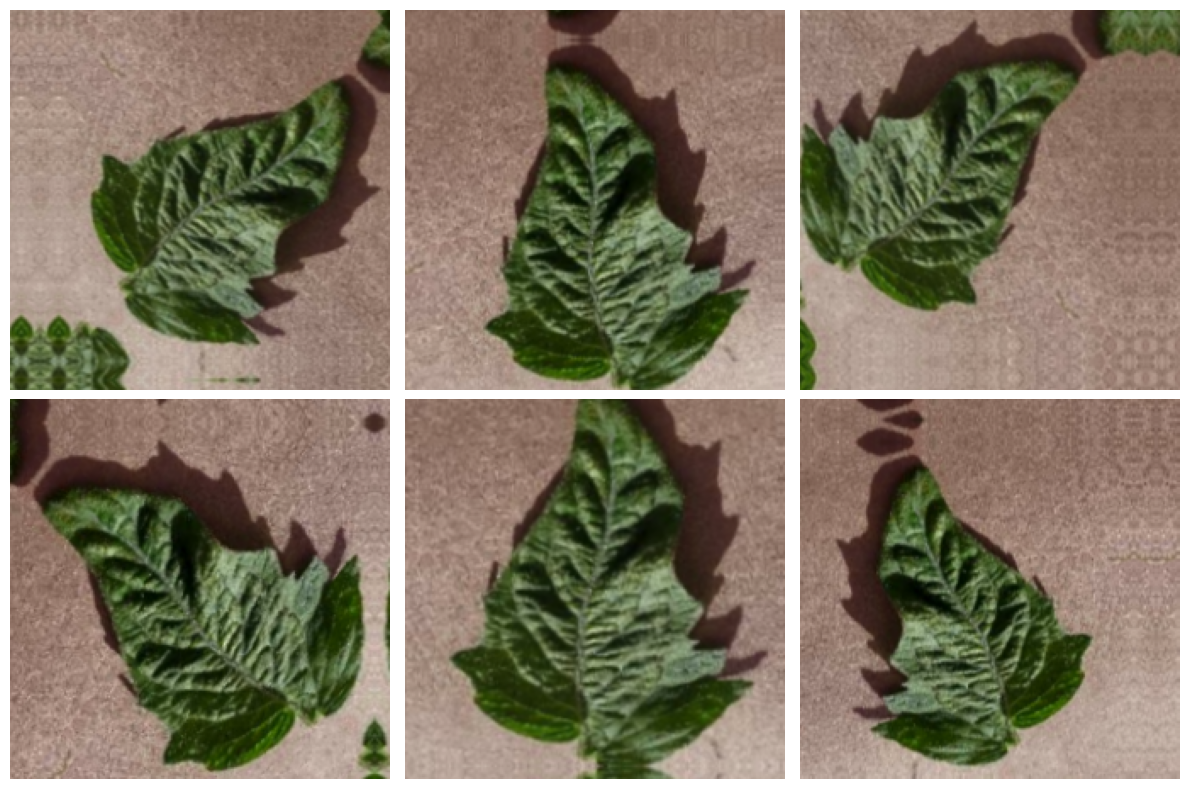

In [ ]:
for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    sample_image = images[0]

    for i in range(6):

        augmented_image = data_augmentation(
            tf.expand_dims(
                sample_image,
                axis=0
            ),
            training=True
        )

        plt.subplot(2, 3, i + 1)

        plt.imshow(
            augmented_image[0].numpy().astype("uint8")
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

    break

In [ ]:
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)
base_model.trainable = False

print("EfficientNetB0 loaded successfully!")
print("Total layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully!
Total layers: 238


In [ ]:
inputs = layers.Input(
    shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,388,538 (16.74 MB)

 Trainable params: 336,407 (1.28 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)
print("✅ Model compiled!")

✅ Model compiled!


In [ ]:
checkpoint = ModelCheckpoint(

    "best_plant_disease_model.keras",

    monitor="val_accuracy",

    save_best_only=True,

    mode="max",

    verbose=1
)

early_stopping = EarlyStopping(

    monitor="val_accuracy",

    patience=5,

    mode="max",

    restore_best_weights=True,

    verbose=1
)

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.3,

    patience=2,

    min_lr=1e-7,

    verbose=1
)

print("✅ Callbacks ready!")

✅ Callbacks ready!


In [ ]:
EPOCHS = 12

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/12
894/894 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6790 - loss: 1.1170
Epoch 1: val_accuracy improved from None to 0.81166, saving model to best_plant_disease_model.keras

Epoch 1: finished saving model to best_plant_disease_model.keras
894/894 ━━━━━━━━━━━━━━━━━━━━ 99s 95ms/step - accuracy: 0.7782 - loss: 0.7301 - val_accuracy: 0.8117 - val_loss: 0.4819 - learning_rate: 0.0010
Epoch 2/12
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.8533 - loss: 0.4704
Epoch 2: val_accuracy improved from 0.81166 to 0.84598, saving model to best_plant_disease_model.keras

Epoch 2: finished saving model to best_plant_disease_model.keras
894/894 ━━━━━━━━━━━━━━━━━━━━ 137s 93ms/step - accuracy: 0.8579 - loss: 0.4465 - val_accuracy: 0.8460 - val_loss: 0.3789 - learning_rate: 0.0010
Epoch 3/12
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.8699 - loss: 0.3932
Epoch 3: val_accuracy improved from 0.84598 to 0.88365, saving model to best_plant_disease_model.keras

Epoch 3: fini

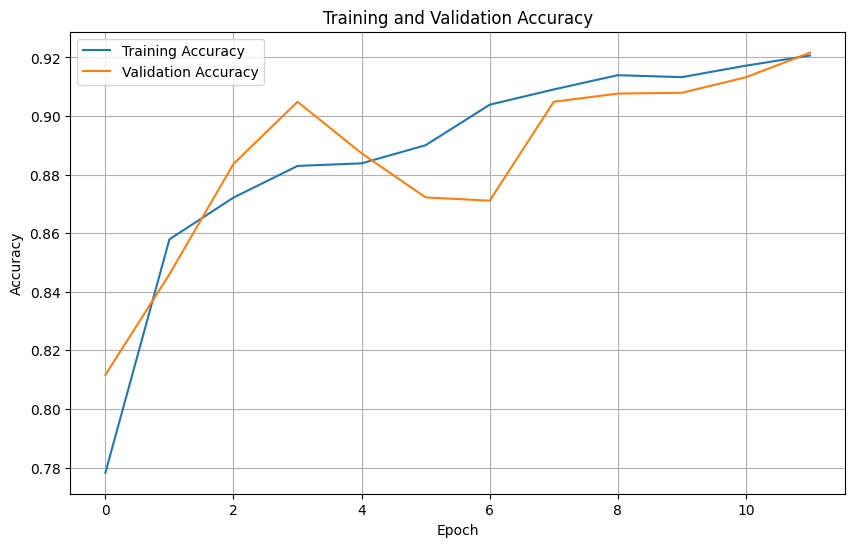

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

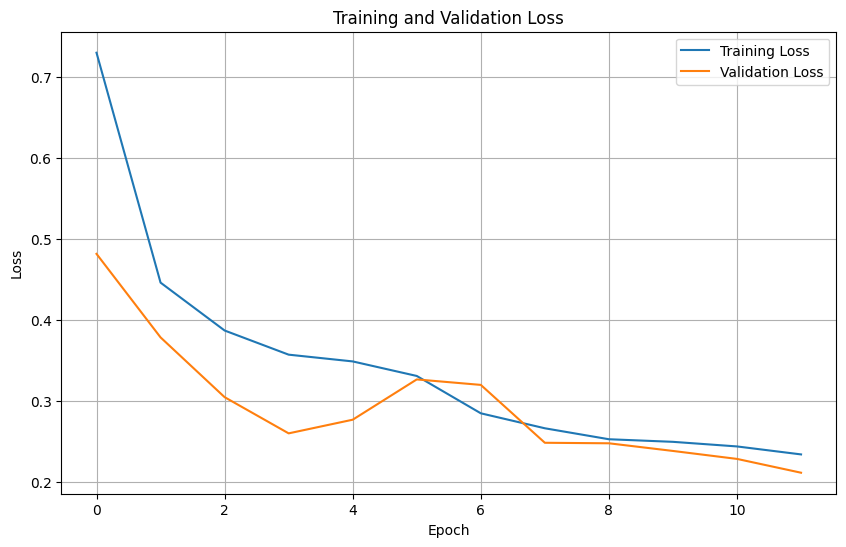

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [ ]:
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-40]:

    layer.trainable = False

print("Total EfficientNet layers:", len(base_model.layers))

trainable_layers = sum(
    1 for layer in base_model.layers
    if layer.trainable
)

print(
    "Trainable EfficientNet layers:",
    trainable_layers
)

Total EfficientNet layers: 238
Trainable EfficientNet layers: 40


In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("✅ Model recompiled for fine-tuning!")

✅ Model recompiled for fine-tuning!


In [ ]:
FINE_TUNE_EPOCHS = 10

initial_epoch = len(
    history.history["loss"]
)

history_fine = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=initial_epoch + FINE_TUNE_EPOCHS,

    initial_epoch=initial_epoch,

    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 13/22
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8106 - loss: 0.6113
Epoch 13: val_accuracy did not improve from 0.92160
894/894 ━━━━━━━━━━━━━━━━━━━━ 117s 115ms/step - accuracy: 0.8350 - loss: 0.5223 - val_accuracy: 0.9110 - val_loss: 0.2330 - learning_rate: 1.0000e-05
Epoch 14/22
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8746 - loss: 0.3796
Epoch 14: val_accuracy improved from 0.92160 to 0.93220, saving model to best_plant_disease_model.keras

Epoch 14: finished saving model to best_plant_disease_model.keras
894/894 ━━━━━━━━━━━━━━━━━━━━ 100s 112ms/step - accuracy: 0.8811 - loss: 0.3580 - val_accuracy: 0.9322 - val_loss: 0.1845 - learning_rate: 1.0000e-05
Epoch 15/22
893/894 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8981 - loss: 0.3067
Epoch 15: val_accuracy improved from 0.93220 to 0.93387, saving model to best_plant_disease_model.keras

Epoch 15: finished saving model to best_plant_disease_model.keras
894/894 ━━━━━━━━━━━━━━━━━━━━ 142s 112ms/s

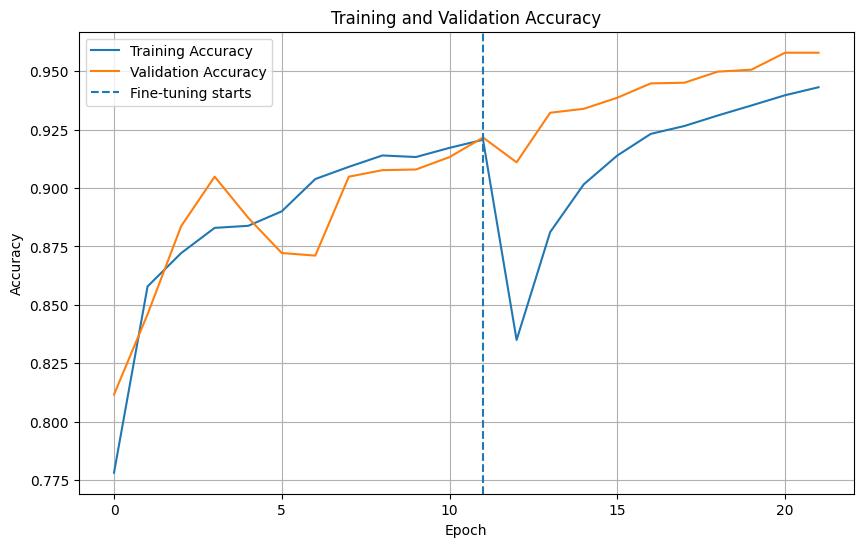

In [ ]:
train_accuracy = (
    history.history["accuracy"]
    +
    history_fine.history["accuracy"]
)

val_accuracy = (
    history.history["val_accuracy"]
    +
    history_fine.history["val_accuracy"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    val_accuracy,
    label="Validation Accuracy"
)

plt.axvline(
    x=len(history.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

In [ ]:
best_model = tf.keras.models.load_model(
    "best_plant_disease_model.keras"
)

print("✅ Best model loaded!")

✅ Best model loaded!


In [ ]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========================================")
print("       FINAL TEST RESULTS")
print("========================================")

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)

print("========================================")

112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 76ms/step - accuracy: 0.9854 - loss: 0.0377

       FINAL TEST RESULTS
Test Loss     : 0.0377
Test Accuracy : 98.54%


In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_labels
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("✅ Predictions generated!")
print("Number of test predictions:", len(y_pred))

✅ Predictions generated!
Number of test predictions: 3561


In [ ]:
unique_labels = np.unique(np.concatenate([y_true, y_pred]))
active_class_names = [class_names[i] for i in unique_labels]

report = classification_report(
    y_true,
    y_pred,
    labels=unique_labels,
    target_names=active_class_names,
    digits=4
)

print(report)

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot     0.0000    0.0000    0.0000         0
                  Tomato_Septoria_leaf_spot     0.0000    0.0000    0.0000         0
Tomato_Spider_mites_Two_spotted_spider_mite     0.0000    0.0000    0.0000         0
                        Tomato__Target_Spot     0.0000    0.0000    0.0000         0
      Tomato__Tomato_YellowLeaf__Curl_Virus     1.0000    0.9831    0.9915      1597
                Tomato__Tomato_mosaic_virus     1.0000    0.9357    0.9668       373
                             Tomato_healthy     0.9994    0.9994    0.9994      1591

                                   accuracy                         0.9854      3561
                                  macro avg     0.4285    0.4169    0.4225      3561
                               weighted avg     0.9997    0.9854    0.9924      3561



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


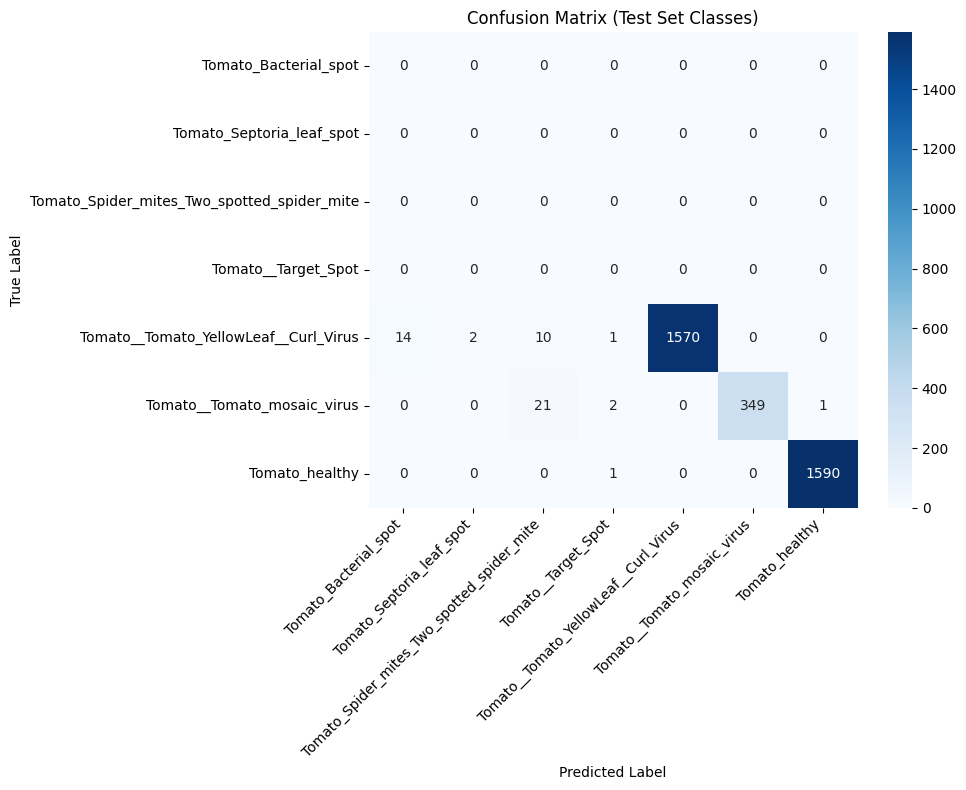

In [ ]:
# Plot Confusion Matrix for active classes in test set
cm = confusion_matrix(y_true, y_pred, labels=unique_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=active_class_names,
    yticklabels=active_class_names
)
plt.title("Confusion Matrix (Test Set Classes)")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
best_model.save(
    "/content/plant_disease_efficientnetb0.keras"
)

print(
    "✅ Model saved successfully!"
)

✅ Model saved successfully!


In [ ]:
from google.colab import files

files.download(
    "/content/plant_disease_efficientnetb0.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

print("Upload a plant leaf image:")

uploaded = files.upload()

image_path = list(
    uploaded.keys()
)[0]

print(
    "\nUploaded image:",
    image_path
)

Upload a plant leaf image:


Saving images (3).jpg to images (3).jpg

Uploaded image: images (3).jpg


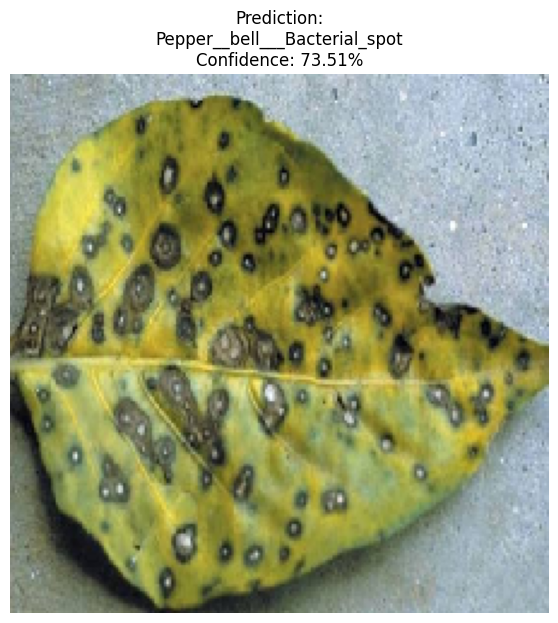

       PLANT DISEASE PREDICTION
Predicted Class: Pepper__bell___Bacterial_spot
Confidence: 73.51%


In [ ]:
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import img_to_array

img = load_img(
    image_path,
    target_size=(
        IMG_SIZE,
        IMG_SIZE
    )
)

img_array = img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

prediction = best_model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index]
    * 100
)

plt.figure(
    figsize=(7, 7)
)

plt.imshow(img)

plt.axis("off")

plt.title(
    f"Prediction:\n{predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

print("==========================================")
print("       PLANT DISEASE PREDICTION")
print("==========================================")

print(
    "Predicted Class:",
    predicted_class
)

print(
    f"Confidence: {confidence:.2f}%"
)

print("==========================================")

In [ ]:
top_5_indices = np.argsort(
    prediction[0]
)[-5:][::-1]

print("==========================================")
print("           TOP 5 PREDICTIONS")
print("==========================================")

for rank, index in enumerate(
    top_5_indices,
    start=1
):

    probability = (
        prediction[0][index]
        * 100
    )

    print(
        f"{rank}. {class_names[index]} "
        f"--> {probability:.2f}%"
    )

print("==========================================")

           TOP 5 PREDICTIONS
1. Pepper__bell___Bacterial_spot --> 73.51%
2. Tomato_Septoria_leaf_spot --> 15.84%
3. Potato___Early_blight --> 8.23%
4. Tomato_Bacterial_spot --> 1.12%
5. Tomato_Early_blight --> 0.48%


In [ ]:
print("\n")
print("====================================================")
print("          PLANT DISEASE DETECTION SYSTEM")
print("====================================================")

print("Dataset              : Plant Disease Detection")
print("Model                : EfficientNetB0")
print("Technique            : Transfer Learning")
print("Fine-Tuning          : Yes")
print("Image Size           : 224 x 224")
print("Number of Classes    :", NUM_CLASSES)
print("Test Accuracy        :", f"{test_accuracy * 100:.2f}%")
print("====================================================")



          PLANT DISEASE DETECTION SYSTEM
Dataset              : Plant Disease Detection
Model                : EfficientNetB0
Technique            : Transfer Learning
Fine-Tuning          : Yes
Image Size           : 224 x 224
Number of Classes    : 23
Test Accuracy        : 98.54%
